In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings 
warnings.filterwarnings('ignore')

In [4]:
df = pd.read_csv('Social_Network_Ads.csv')

In [5]:
df.head()

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Age              400 non-null    int64
 1   EstimatedSalary  400 non-null    int64
 2   Purchased        400 non-null    int64
dtypes: int64(3)
memory usage: 9.5 KB


In [8]:
df.isnull().sum()

Age                0
EstimatedSalary    0
Purchased          0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(33)

In [14]:
df.describe()

,Age,EstimatedSalary,Purchased
count,400.000000,400.000000,400.000000
mean,37.655000,69742.500000,0.357500
std,10.482877,34096.960282,0.479864
min,18.000000,15000.000000,0.000000
25%,29.750000,43000.000000,0.000000
50%,37.000000,70000.000000,0.000000
75%,46.000000,88000.000000,1.000000
max,60.000000,150000.000000,1.000000


In [16]:
def plotting (var , num):
    plt.subplot(2,2,num)
    sns.histplot(df[var] , kde=True)

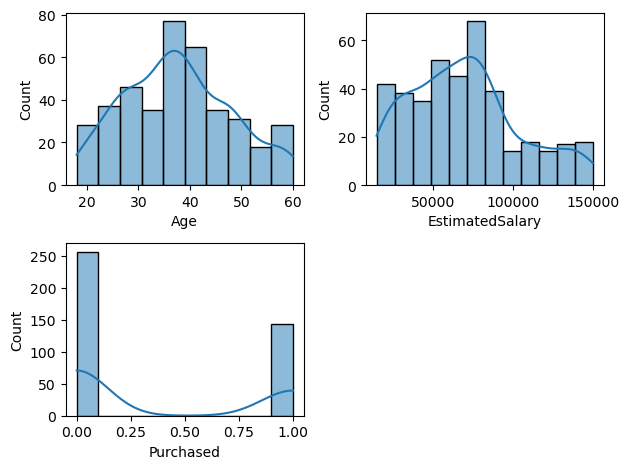

In [18]:
plotting('Age' , 1)
plotting('EstimatedSalary' ,2 )
plotting('Purchased' , 3) 
plt.tight_layout()

In [24]:
df.head()

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0


In [31]:
X = df.drop('Purchased' , axis=1)
y = df['Purchased']

In [32]:
from sklearn.model_selection import train_test_split

In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [34]:
from sklearn.preprocessing import StandardScaler

In [35]:
scaler = StandardScaler()

In [36]:
X_train_scaled  =scaler.fit_transform(X_train)
X_test_scaled  =scaler.fit_transform(X_test)

In [41]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

In [48]:
models = {
    'logistic regression':LogisticRegression(),
    'Knn ': KNeighborsClassifier(),
    'naive bayes' :GaussianNB(), 
    'decision tree':DecisionTreeClassifier(),
    'svm' :SVC(probability = True)
}

In [50]:
results =[]

In [52]:
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    
    results.append({
        'model': name,
        'accuracy': round(acc, 4),
        'f1': round(f1, 4)
    })

In [53]:
results

[{'model': 'logistic regression', 'accuracy': 0.8, 'f1': 0.6667},
 {'model': 'Knn ', 'accuracy': 0.8875, 'f1': 0.8475},
 {'model': 'naive bayes', 'accuracy': 0.85, 'f1': 0.7778},
 {'model': 'decision tree', 'accuracy': 0.9, 'f1': 0.8571},
 {'model': 'svm', 'accuracy': 0.8875, 'f1': 0.8475}]